# LUMI / Uni-Mol — 完全獨立 Jupyter CPU 測試流程

**使用場景：** 另一台 HPC 的 Jupyter Notebook、**沒有 GPU、沒有 GUI、沒有預先下載模型**。本 Notebook **沒有任何 `sbatch`、`srun` 或 `--partition` 命令**；所有結果在 cell 下直接顯示。

**測試路徑：** Python / RDKit → SMILES → 3D conformers → LMDB → GitHub source / Uni-Core → LUMI data loader → **隨機初始化** LUMI mini-model → CPU forward/backward → loss chart / checkpoint。

> 重要：這是原始 LUMI 模型的 **CPU 縮小版工程 smoke test**，不是 1,300 萬分子的正式 pretraining。Notebook 會嘗試安裝所需套件，但若 HPC 沒有對外網路或權限，安裝必須改用校內 mirror/既有環境。**不下載 pretrained model weights**。

使用前：在 JupyterHub 選 **CPU server/kernel**；若 JupyterHub 自身還沒啟動就顯示 GPU partition 錯誤，需在 Hub 啟動頁面選 CPU profile/向管理員確認，而不是修改這份 Notebook。

## 0. 設定（第一次使用）

首次使用保持 `INSTALL_PACKAGES=True`、`DOWNLOAD_GITHUB=True`。只要你已經完成安裝，下次可以改成 `False`。修改 cell 後從頭順序執行。資料和結果只會寫到這份 Notebook 旁的 `lumi_notebook_workspace/`。

In [1]:
from pathlib import Path
import os, sys, platform, subprocess, importlib, importlib.util, traceback, json, time, shutil
from IPython.display import display, Markdown

INSTALL_PACKAGES = True
DOWNLOAD_GITHUB = True
RUN_MODEL_TESTS = True
MINI_TRAIN_STEPS = 3
SEED = 42

ROOT = Path.cwd().resolve()
WORK = ROOT / "lumi_notebook_workspace"
SOURCE = WORK / "sources"
DATA = WORK / "data"
LOGS = WORK / "logs"
OUTPUT = WORK / "results"
for d in [SOURCE, DATA, LOGS, OUTPUT]: d.mkdir(parents=True,exist_ok=True)
STATUS = {}

def mark(name, status, details=""):
    STATUS[name] = {"test":name,"status":status,"details":str(details)}
    print(f"{'✅' if status=='PASS' else '⚠️' if status=='SKIPPED' else '❌'} {status}: {name}  {details}")

def execute(cmd, label, cwd=ROOT, env=None, timeout=900):
    cmd=list(map(str,cmd))
    print("$", " ".join(cmd))
    try:
        p=subprocess.run(cmd, cwd=str(cwd), capture_output=True, text=True, env=env, timeout=timeout)
        output=(p.stdout or '')+'\n'+(p.stderr or '')
        (LOGS/f"{label}.log").write_text(output,encoding="utf-8")
        print(output[-2400:] if output.strip() else '(no output)')
        print('Exit code:', p.returncode)
        return p.returncode==0
    except Exception as e:
        (LOGS/f"{label}.log").write_text(repr(e),encoding="utf-8")
        print(type(e).__name__, e)
        return False

print("Python:", sys.executable)
print("Notebook directory:", ROOT)
print("Workspace:", WORK)
print("GPU partition requested? NO")

Python: /mnt/software/jupyter/5.7.2/bin/python
Notebook directory: /mnt/home/ypan/heart_liver/model/pretrain_jupytor
Workspace: /mnt/home/ypan/heart_liver/model/pretrain_jupytor/lumi_notebook_workspace
GPU partition requested? NO


## 1. 顯示目前的 HPC / Kernel 環境

`CUDA available=False` 屬於正常的 CPU Notebook，不是錯誤。這份 Notebook 不要求 GPU partition。

In [2]:
try:
    import pandas as pd
except ImportError:
    pd = None

def ver(name):
    try: return getattr(importlib.import_module(name),'__version__','installed')
    except Exception: return '(not available)'

rows=[('OS',platform.platform()),('Python',platform.python_version()),('Kernel',sys.executable),
      ('SLURM Job ID',os.getenv('SLURM_JOB_ID','not running under SLURM')),
      ('GPU requested','No'),('PyTorch',ver('torch')),('RDKit',ver('rdkit')),('LMDB',ver('lmdb')),
      ('Git',shutil.which('git') or 'not found')]
display(pd.DataFrame(rows,columns=['Item','Value'])) if pd is not None else print(*rows,sep='\n')
mark('Jupyter CPU kernel','PASS')

('OS', 'Linux-4.18.0-553.150.1.el8_10.x86_64-x86_64-with-glibc2.28')
('Python', '3.11.9')
('Kernel', '/mnt/software/jupyter/5.7.2/bin/python')
('SLURM Job ID', '1010519')
('GPU requested', 'No')
('PyTorch', '(not available)')
('RDKit', '(not available)')
('LMDB', '(not available)')
('Git', 'not found')
✅ PASS: Jupyter CPU kernel  


## 2. 安裝依賴到**目前 Notebook Kernel**（首次才需要）

使用 `sys.executable -m pip` 保證安裝位置和 Notebook 使用的 Python 相同。**不要在 Notebook 內建立不同的 Conda 環境後仍使用舊 kernel**。若 Python 版本或 HPC 權限不允許安裝，本格會顯示錯誤；後續測試需先修正環境或改用新的 Jupyter kernel。

In [3]:
# Installed in the active Jupyter kernel; no GPUs, CUDA or SLURM required.
SCIENCE = ['numpy>=1.24,<2','pandas>=1.5,<2.3','scipy<1.14',
           'rdkit>=2023.9,<2025','lmdb>=1.4,<2','matplotlib>=3.6,<4',
           'tqdm<5','pillow','pyyaml<7','iopath<1',
           'tensorboardX<3','scikit-learn>=1.3,<1.6','omegaconf<3',
           'hydra-core<2','packaging<26','ml_collections<2','ipython']
if INSTALL_PACKAGES:
    missing=[pkg for pkg in ['rdkit','lmdb','numpy','pandas','scipy','matplotlib']
             if importlib.util.find_spec(pkg) is None]
    if missing:
        ok=execute([sys.executable,'-m','pip','install',*SCIENCE], 'install_science',timeout=1600)
        mark('Scientific dependencies','PASS' if ok else 'FAIL','restart kernel if required')
    else:
        mark('Scientific dependencies','PASS','already importable')
    if importlib.util.find_spec('torch') is None:
        # 2.2.2 is compatible with Python 3.9–3.11; Python 3.12+ needs newer torch.
        torch_spec = 'torch==2.2.2' if sys.version_info[:2] <= (3,11) else 'torch'
        ok=execute([sys.executable,'-m','pip','install',torch_spec,
                    '--index-url','https://download.pytorch.org/whl/cpu'],
                   'install_torch_cpu',timeout=2400)
        mark('CPU PyTorch','PASS' if ok else 'FAIL')
    else:
        mark('CPU PyTorch','PASS','existing PyTorch will be run on CPU')
else:
    mark('Dependency install','SKIPPED','INSTALL_PACKAGES=False')
print('RDKit import:', ver('rdkit'), '| torch:',ver('torch'),'| lmdb:',ver('lmdb'))

$ /mnt/software/jupyter/5.7.2/bin/python -m pip install numpy>=1.24,<2 pandas>=1.5,<2.3 scipy<1.14 rdkit>=2023.9,<2025 lmdb>=1.4,<2 matplotlib>=3.6,<4 tqdm<5 pillow pyyaml<7 iopath<1 tensorboardX<3 scikit-learn>=1.3,<1.6 omegaconf<3 hydra-core<2 packaging<26 ml_collections<2 ipython
 MB/s eta 0:00:00
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached kiwisolver-1.5.1-cp311-cp311-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (1.4 MB)
Using cached protobuf-7.36.2-cp310-abi3-manylinux2014_x86_64.whl (343 kB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
Using cached pytz-2026.5-py2.py3-none-any.whl (506 kB)
Using cached threadpoolctl-3.7.0-py3-none-any.whl (26 kB)
Using cached tzdata-2026.5-py2.py3-none-any.whl (347 kB)
Using cached absl_py-2.5.1-py3-none-any.whl (137 kB)
Using cached portalocker-4.4.1-py3-none-any.whl (129 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
  Created wheel for iopath: filename=iopath-0.1.10-py3-none-any.whl size=31532 sha2

## 3. RDKit — SMILES parsing 與分子圖（不用 GitHub 原始碼）

先用 8 個內建的正確 SMILES 加 1 個故意錯誤的 SMILES。這樣即使 HPC 不允許連 GitHub，也能完成前半段資料測試。

[13:16:42] SMILES Parse Error: unclosed ring for input: 'C1CC'


,Name,SMILES,Valid,Heavy atoms,Canonical
0,Ethanol,CCO,True,3.0,CCO
1,Benzene,c1ccccc1,True,6.0,c1ccccc1
2,Acetic acid,CC(=O)O,True,4.0,CC(=O)O
3,Pyridine,c1ccncc1,True,6.0,c1ccncc1
4,Cyclohexane,C1CCCCC1,True,6.0,C1CCCCC1
5,L-Alanine,C[C@@H](N)C(=O)O,True,6.0,C[C@@H](N)C(=O)O
6,Triethylamine,CCN(CC)CC,True,7.0,CCN(CC)CC
7,Lipid-like amine,CCCCCCCCCCCCN(C)C,True,15.0,CCCCCCCCCCCCN(C)C
8,Broken SMILES,C1CC,False,NaN,None


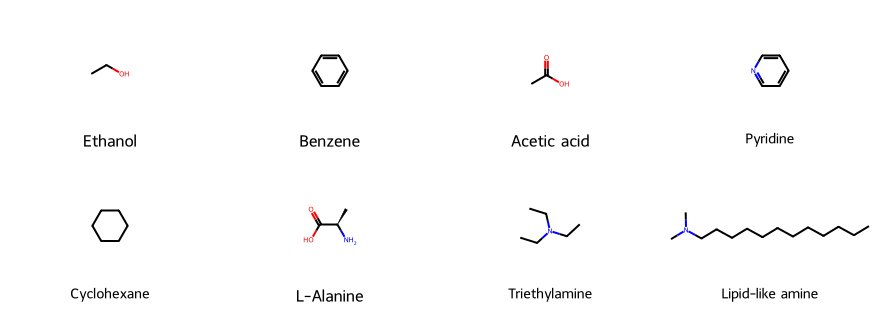

✅ PASS: RDKit SMILES parsing  8 valid; 1 invalid rejected as expected


In [4]:
import numpy as np
import pandas as pd  # Installed in Section 2 if missing
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from IPython.display import display
TEST_SMILES = [
 ('Ethanol','CCO'), ('Benzene','c1ccccc1'), ('Acetic acid','CC(=O)O'),
 ('Pyridine','c1ccncc1'), ('Cyclohexane','C1CCCCC1'),
 ('L-Alanine','C[C@@H](N)C(=O)O'), ('Triethylamine','CCN(CC)CC'),
 ('Lipid-like amine','CCCCCCCCCCCCN(C)C'), ('Broken SMILES','C1CC')]
parse_rows=[]; draw_mols=[]; draw_names=[]
for name, smiles in TEST_SMILES:
    mol=Chem.MolFromSmiles(smiles)
    valid=mol is not None
    parse_rows.append({'Name':name,'SMILES':smiles,'Valid':valid,
                       'Heavy atoms':mol.GetNumHeavyAtoms() if valid else None,
                       'Canonical':Chem.MolToSmiles(mol,isomericSmiles=True) if valid else None})
    if valid:
        draw_mols.append(mol);draw_names.append(name)
parse_df=pd.DataFrame(parse_rows)
display(parse_df)
display(Draw.MolsToGridImage(draw_mols,legends=draw_names,molsPerRow=4,subImgSize=(220,155)))
assert sum(parse_df.Valid)==8 and not parse_df.iloc[-1].Valid
mark('RDKit SMILES parsing','PASS','8 valid; 1 invalid rejected as expected')

## 4. RDKit — 3D conformers / 幾何品質 / 圖表

對每個有效分子用 ETKDGv3 產生 2 個 3D conformers，檢查形狀、有限座標、原子清單與不同構型。這是簡化測試，與 LUMI 論文的正式 conformer 設定不同。**為避免重複 2D views，我們不在 LMDB 加 2D conformer；LUMI 的 `Add2DConformerDataset` 會在 training loader 裡處理。**

,Molecule,Status,Atoms,3D views,Mean xyz difference
0,Ethanol,PASS,9,2,1.055217
1,Benzene,PASS,12,2,2.350067
2,Acetic acid,PASS,8,2,0.777984
3,Pyridine,PASS,11,2,0.166814
4,Cyclohexane,PASS,18,2,2.372605
5,L-Alanine,PASS,13,2,2.216498
6,Triethylamine,PASS,22,2,4.145205
7,Lipid-like amine,PASS,46,2,2.071357


✅ PASS: RDKit ETKDG conformers  8/8 built


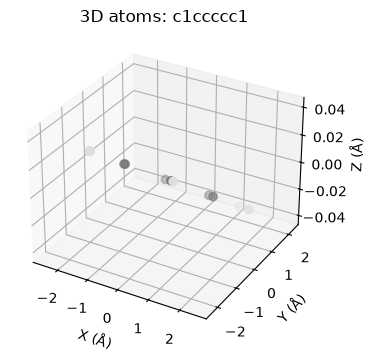

In [5]:
import matplotlib.pyplot as plt
records=[]; geom_rows=[]
for row in parse_df.loc[parse_df.Valid].itertuples():
    mol=Chem.AddHs(Chem.MolFromSmiles(row.SMILES))
    params=AllChem.ETKDGv3(); params.randomSeed=SEED; params.numThreads=1
    ids=list(AllChem.EmbedMultipleConfs(mol,numConfs=2,params=params))
    if len(ids)<2:
        geom_rows.append({'Molecule':row.Name,'Status':'FAIL','3D views':len(ids)}); continue
    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMoleculeConfs(mol,maxIters=100)
    atoms=[a.GetSymbol() for a in mol.GetAtoms()]
    xyzs=[mol.GetConformer(cid).GetPositions().astype('float32') for cid in ids]
    valid=all(x.shape==(len(atoms),3) and np.isfinite(x).all() for x in xyzs)
    geom_rows.append({'Molecule':row.Name,'Status':'PASS' if valid else 'FAIL',
                      'Atoms':len(atoms),'3D views':len(xyzs),
                      'Mean xyz difference':float(np.linalg.norm(xyzs[0]-xyzs[1],axis=1).mean())})
    if valid:
        records.append({'atoms':atoms,'coordinates':xyzs,
                        'smi':Chem.MolToSmiles(Chem.RemoveHs(mol),isomericSmiles=True)})
display(pd.DataFrame(geom_rows))
mark('RDKit ETKDG conformers','PASS' if len(records)==8 else 'FAIL',f'{len(records)}/8 built')

# Inline 3D plot works even when HPC has no desktop graphical interface
if records:
    ex=records[1]; xyz=ex['coordinates'][0]
    fig=plt.figure(figsize=(6,4)); ax=fig.add_subplot(111,projection='3d')
    atom_col={'C':'#737373','O':'#e85b5b','N':'#5b83da','H':'#dddddd'}
    ax.scatter(xyz[:,0],xyz[:,1],xyz[:,2],
               c=[atom_col.get(atom,'#777777') for atom in ex['atoms']],s=36)
    ax.set(title=f"3D atoms: {ex['smi']}",xlabel='X (Å)',ylabel='Y (Å)',zlabel='Z (Å)')
    plt.show()

## 5. LMDB — Train/valid、資料讀取與品質表格

LMDB 使用 **numeric ASCII keys** `b'0', b'1', ...`，資料為 `{'atoms': ..., 'coordinates': ..., 'smi': ...}`。這裡先不依賴官方 DataLoader，可單獨確認 round trip、座標與 split 沒有重複分子。

In [6]:
import lmdb, pickle
assert len(records)==8, '請先完成 RDKit 3D 測試'
LMDB_DIR=DATA/'lmdb'
LMDB_DIR.mkdir(parents=True,exist_ok=True)
ordered=sorted(records,key=lambda r:r['smi'])
parts={'train':ordered[:6], 'valid':ordered[6:]}
for split,items in parts.items():
    path=LMDB_DIR/(split+'.lmdb')
    if path.exists(): path.unlink()  # Only overwrite notebook test artifacts
    env=lmdb.open(str(path),map_size=64*1024*1024,subdir=False)
    with env.begin(write=True) as txn:
        for i,item in enumerate(items):
            txn.put(str(i).encode('ascii'),pickle.dumps(item,protocol=4))
    env.close()
roundtrip=[]
for split,items in parts.items():
    env=lmdb.open(str(LMDB_DIR/(split+'.lmdb')),subdir=False,readonly=True,lock=False)
    with env.begin() as txn:
        assert txn.stat()['entries']==len(items)
        for i in range(len(items)):
            rec=pickle.loads(txn.get(str(i).encode('ascii')))
            for xyz in rec['coordinates']:
                assert np.asarray(xyz).shape==(len(rec['atoms']),3)
                assert np.isfinite(xyz).all()
            roundtrip.append({'Split':split,'SMILES':rec['smi'],
                              'Atoms':len(rec['atoms']),'3D views':len(rec['coordinates'])})
    env.close()
check_df=pd.DataFrame(roundtrip)
display(check_df)
assert set(check_df[check_df.Split=='train'].SMILES).isdisjoint(
       set(check_df[check_df.Split=='valid'].SMILES))
mark('LMDB roundtrip & split','PASS','6 train / 2 valid')

,Split,SMILES,Atoms,3D views
0,train,C1CCCCC1,18,2
1,train,CC(=O)O,8,2
2,train,CCCCCCCCCCCCN(C)C,46,2
3,train,CCN(CC)CC,22,2
4,train,CCO,9,2
5,train,C[C@@H](N)C(=O)O,13,2
6,valid,c1ccccc1,12,2
7,valid,c1ccncc1,11,2


✅ PASS: LMDB roundtrip & split  6 train / 2 valid


## 6. 從 GitHub 下載 LUMI / Uni-Mol / Uni-Core source（**不下載權重**）

只有從這格開始才需要 GitHub 網路。啟用 `GIT_LFS_SKIP_SMUDGE=1`，跳過 repository 裡的 LFS checkpoint 權重；記錄實際 commit。若 HPC 禁止外網，先向管理員確認核准的鏡像，**不要跳過檢查假裝已下載**。

In [10]:
import urllib.request
import zipfile
import io
from pathlib import Path
# Use the current Jupyter working directory
BASE = Path.cwd() / "lumi_notebook_workspace"
SOURCE = BASE / "sources"
SOURCE.mkdir(parents=True, exist_ok=True)
repos = {
   "LUMI-lab": "bowenli-lab/LUMI-lab",
   "Uni-Mol": "deepmodeling/Uni-Mol",
   "Uni-Core": "dptech-corp/Uni-Core",
}
for name, repo in repos.items():
   dest = SOURCE / name
   if dest.exists():
       print(f"SKIP: {name} already exists")
       continue
   success = False
   for branch in ("main", "master"):
       url = f"https://api.github.com/repos/{repo}/zipball/{branch}"
       try:
           print(f"Downloading {name} ({branch})...")
           req = urllib.request.Request(
               url,
               headers={"User-Agent": "LUMI-HPC-Test"}
           )
           with urllib.request.urlopen(req, timeout=120) as r:
               data = r.read()
           with zipfile.ZipFile(io.BytesIO(data)) as z:
               roots = {
                   p.split("/")[0]
                   for p in z.namelist() if "/" in p
               }
               if len(roots) != 1:
                   raise ValueError("Unexpected ZIP structure")
               root = next(iter(roots))
               z.extractall(SOURCE)
           (SOURCE / root).rename(dest)
           print(f"PASS: {name} -> {dest}")
           success = True
           break
       except Exception as e:
           print(f"Attempt failed: {type(e).__name__}: {e}")
   if not success:
       print(f"FAILED: {name}")
print("\nDownload stage complete")

PASS: LUMI-lab -> /mnt/home/ypan/heart_liver/model/pretrain_jupytor/lumi_notebook_workspace/sources/LUMI-lab
PASS: Uni-Mol -> /mnt/home/ypan/heart_liver/model/pretrain_jupytor/lumi_notebook_workspace/sources/Uni-Mol
PASS: Uni-Core -> /mnt/home/ypan/heart_liver/model/pretrain_jupytor/lumi_notebook_workspace/sources/Uni-Core

Download stage complete


In [11]:
from pathlib import Path
SOURCE = Path.cwd() / "lumi_notebook_workspace" / "sources"
for name in ["LUMI-lab", "Uni-Mol", "Uni-Core"]:
   folder = SOURCE / name
   files = list(folder.iterdir()) if folder.exists() else []
   print(
       name,
       "FOUND" if files else "MISSING",
       "Files:", len(files)
   )

LUMI-lab FOUND Files: 12
Uni-Mol FOUND Files: 11
Uni-Core FOUND Files: 13


In [14]:
BASE = Path.cwd() / "lumi_notebook_workspace"
SOURCE = BASE / "sources"
DOWNLOAD_GITHUB = False
for name in ["LUMI-lab", "Uni-Mol", "Uni-Core"]:
   path = SOURCE / name
   assert path.is_dir(), f"Missing: {path}"
   print("READY:", name)

READY: LUMI-lab
READY: Uni-Mol
READY: Uni-Core


In [16]:
paths = {
   "Uni-Core setup": SOURCE / "Uni-Core" / "setup.py",
   "Uni-Mol data": SOURCE / "Uni-Mol" / "unimol" / "data",
   "LUMI model": SOURCE / "LUMI-lab" / "model",
   "LUMI pretrain": SOURCE / "LUMI-lab" / "model" / "pretrain",
}
for name, path in paths.items():
   print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")
   print(" ", path)

Uni-Core setup: FOUND
  /mnt/home/ypan/heart_liver/model/pretrain_jupytor/lumi_notebook_workspace/sources/Uni-Core/setup.py
Uni-Mol data: MISSING
  /mnt/home/ypan/heart_liver/model/pretrain_jupytor/lumi_notebook_workspace/sources/Uni-Mol/unimol/data
LUMI model: FOUND
  /mnt/home/ypan/heart_liver/model/pretrain_jupytor/lumi_notebook_workspace/sources/LUMI-lab/model
LUMI pretrain: FOUND
  /mnt/home/ypan/heart_liver/model/pretrain_jupytor/lumi_notebook_workspace/sources/LUMI-lab/model/pretrain


In [12]:
import shutil
import urllib.request
import urllib.error
print("Git installed:", shutil.which("git"))
urls = {
   "GitHub": "https://github.com",
   "GitHub Raw": "https://raw.githubusercontent.com",
   "GitHub API": "https://api.github.com",
   "PyPI": "https://pypi.org",
}
for name, url in urls.items():
   try:
       req = urllib.request.Request(
           url,
           headers={"User-Agent": "Python-HPC-Test"}
       )
       with urllib.request.urlopen(req, timeout=8) as response:
           print(f"{name}: ACCESSIBLE ({response.status})")
   except Exception as e:
       print(f"{name}: FAILED ({type(e).__name__}: {e})")

Git installed: None
GitHub: ACCESSIBLE (200)
GitHub Raw: ACCESSIBLE (200)
GitHub API: ACCESSIBLE (200)
PyPI: ACCESSIBLE (200)


In [13]:
REPOS={
 'LUMI-lab':'https://github.com/bowenli-lab/LUMI-lab.git',
 'Uni-Mol':'https://github.com/deepmodeling/Uni-Mol.git',
 'Uni-Core':'https://github.com/dptech-corp/Uni-Core.git'}
source_rows=[]
for name,url in REPOS.items():
    dest=SOURCE/name
    if (dest/'.git').is_dir():
        ok=True; print('ALREADY DOWNLOADED:',name)
    elif DOWNLOAD_GITHUB:
        env=dict(os.environ,GIT_LFS_SKIP_SMUDGE='1',GIT_TERMINAL_PROMPT='0')
        ok=execute(['git','-c','filter.lfs.smudge=',
                    '-c','filter.lfs.required=false','clone','--depth','1',url,dest],
                   'git_'+name.replace('-','_'),env=env,timeout=1200)
    else:
        ok=False
    commit='not available'
    if (dest/'.git').is_dir():
        p=subprocess.run(['git','rev-parse','HEAD'],cwd=dest,text=True,capture_output=True)
        if p.returncode==0: commit=p.stdout.strip()
    source_rows.append({'Repository':name,'Present':ok,'Commit':commit})
mark('GitHub sources','PASS' if all(x['Present'] for x in source_rows) else 'FAIL',
     'No pretrained checkpoints fetched')
display(pd.DataFrame(source_rows))

$ git -c filter.lfs.smudge= -c filter.lfs.required=false clone --depth 1 https://github.com/bowenli-lab/LUMI-lab.git /mnt/home/ypan/heart_liver/model/pretrain_jupytor/lumi_notebook_workspace/sources/LUMI-lab
FileNotFoundError [Errno 2] No such file or directory: 'git'
$ git -c filter.lfs.smudge= -c filter.lfs.required=false clone --depth 1 https://github.com/deepmodeling/Uni-Mol.git /mnt/home/ypan/heart_liver/model/pretrain_jupytor/lumi_notebook_workspace/sources/Uni-Mol
FileNotFoundError [Errno 2] No such file or directory: 'git'
$ git -c filter.lfs.smudge= -c filter.lfs.required=false clone --depth 1 https://github.com/dptech-corp/Uni-Core.git /mnt/home/ypan/heart_liver/model/pretrain_jupytor/lumi_notebook_workspace/sources/Uni-Core
FileNotFoundError [Errno 2] No such file or directory: 'git'
❌ FAIL: GitHub sources  No pretrained checkpoints fetched


,Repository,Present,Commit
0,LUMI-lab,False,not available
1,Uni-Mol,False,not available
2,Uni-Core,False,not available


## 7. 安裝 Uni-Core + 準備缺少的 `unimol/data/` 與字典

使用與 LUMI 相關的 upstream source 補全 data module（**可能版本不相容**）。這格會明確印出結果，不會偷偷替換其他 code 或下載 checkpoint。若 LUMI import 失敗，先查看下一格的錯誤。

In [8]:
CORE=SOURCE/'Uni-Core'
if (CORE/'setup.py').exists():
    if importlib.util.find_spec('unicore') is None and INSTALL_PACKAGES:
        ok=execute([sys.executable,'-m','pip','install','--no-build-isolation','--no-deps',
                    '-e',str(CORE)],'install_unicore',timeout=1200)
    else:
        ok=importlib.util.find_spec('unicore') is not None
    mark('Uni-Core import/install','PASS' if ok else 'FAIL')
else:
    mark('Uni-Core import/install','FAIL','Uni-Core source unavailable')

UP=SOURCE/'Uni-Mol'/'unimol'/'unimol'/'data'
LUMI_DATA=SOURCE/'LUMI-lab'/'model'/'unimol'/'data'
SRC_DICT=SOURCE/'Uni-Mol'/'unimol'/'example_data'/'molecule'/'dict.txt'
if UP.is_dir() and (SOURCE/'LUMI-lab'/'model'/'unimol').is_dir():
    if not LUMI_DATA.exists(): shutil.copytree(UP,LUMI_DATA)
    if SRC_DICT.is_file(): shutil.copy2(SRC_DICT,LMDB_DIR/'dict.txt')
    ok=LUMI_DATA.is_dir() and (LMDB_DIR/'dict.txt').is_file()
    mark('LUMI data module + atom dictionary','PASS' if ok else 'FAIL')
else:
    mark('LUMI data module + atom dictionary','FAIL','Source tree unavailable')

# Write provenance to results directory
(OUTPUT/'source_provenance.json').write_text(json.dumps(source_rows,indent=2))

❌ FAIL: Uni-Core import/install  Uni-Core source unavailable
❌ FAIL: LUMI data module + atom dictionary  Source tree unavailable


274

## 8. 真正的 LUMI import 相容性報告

不使用 `unimol_tools` 代替 LUMI。如果原始碼或依賴不完整，顯示 FAIL，之後的 LUMI model tests 就會 SKIP；前面的 RDKit 和 LMDB 表格仍完整保存。

In [ ]:
LUMI_MODEL_DIR=SOURCE/'LUMI-lab'/'model'
if LUMI_MODEL_DIR.is_dir() and str(LUMI_MODEL_DIR) not in sys.path:
    sys.path.insert(0,str(LUMI_MODEL_DIR))
needed=['torch','unicore','unimol','unimol.data',
        'unimol.tasks.unimol_contrastive',
        'unimol.models.unimol_contrastive',
        'unimol.losses.unimol_contrastive']
imp=[]
for modname in needed:
    try:
        mod=importlib.import_module(modname)
        imp.append({'Module':modname,'Status':'PASS','Error':''})
    except Exception as e:
        imp.append({'Module':modname,'Status':'FAIL','Error':f'{type(e).__name__}: {e}'[:220]})
imp_df=pd.DataFrame(imp); display(imp_df)
LUMI_READY=all(x['Status']=='PASS' for x in imp) and (LMDB_DIR/'dict.txt').is_file()
mark('LUMI dependency compatibility','PASS' if LUMI_READY else 'FAIL',
     'if failed, fix dependencies before training')

## 9. LUMI Contrastive Dataset Loader（CPU）

真實使用 LUMI 的 `UniMolTaskContrastive`，從 LMDB 讀取兩個分子的兩個 views，並列出 input tensor 形狀及正樣本配對。這是 **真正的 LUMI DataLoader**，不是 mock。

In [ ]:
import torch
from types import SimpleNamespace
TASK=None; BATCH=None
if not LUMI_READY:
    mark('LUMI paired-view DataLoader','SKIPPED','dependency imports not ready')
else:
    try:
        from unimol.tasks.unimol_contrastive import UniMolTaskContrastive
        args=SimpleNamespace(data=str(LMDB_DIR),dict_name='dict.txt',seed=SEED,
            only_polar=0,remove_hydrogen=False,remove_polar_hydrogen=False,
            mode='train',max_atoms=256,max_seq_len=256,
            mask_prob=0.4,leave_unmasked_prob=0.0,random_token_prob=0.0,
            noise_type='uniform',noise=0.5,contrastive_loss=1.0)
        TASK=UniMolTaskContrastive.setup_task(args)
        TASK.load_dataset('train')
        d=TASK.dataset('train')
        BATCH=d.collater([d[0],d[1]])
        names=list(BATCH['target']['smi_name'])
        assert BATCH['net_input']['src_tokens'].shape[0]==4
        assert names[:2]==names[2:],f'view pairing order unexpected: {names}'
        display(pd.DataFrame([
          {'Tensor':key,'Shape':tuple(val.shape)}
          for key,val in BATCH['net_input'].items() if isinstance(val,torch.Tensor)]))
        display(pd.DataFrame({'View1':names[:2],'View2':names[2:]}))
        mask_count=int(BATCH['target']['tokens_target'].ne(TASK.dictionary.pad()).sum())
        assert mask_count>0
        mark('LUMI paired-view DataLoader','PASS',f'2 molecules / 4 views; masked atoms {mask_count}')
    except Exception as e:
        (LOGS/'loader_error.txt').write_text(traceback.format_exc())
        print(traceback.format_exc(limit=7))
        mark('LUMI paired-view DataLoader','FAIL',str(e))
        TASK=None; BATCH=None

## 10. LUMI 小型 Transformer — **CPU 隨機初始化** Forward + Backward

我們只測試工程功能：**1 layer、64 hidden dimension、4 heads**，不載入任何 pretrained weights。正式 LUMI model 比這個測試設定大很多。這裡測試原始自訂 model + loss，而不是替代的玩具模型。

In [ ]:
MODEL=None; CRITERION=None; OPTIMIZER=None
if not RUN_MODEL_TESTS or TASK is None or BATCH is None:
    mark('LUMI CPU forward/backward','SKIPPED','disabled or loader unavailable')
else:
    try:
        from unimol.models.unimol_contrastive import UniMolModelContrastive
        from unimol.losses.unimol_contrastive import UniMolLossContrastive
        torch.set_num_threads(min(2,os.cpu_count() or 1)); torch.manual_seed(SEED)
        cfg=TASK.args
        cfg.encoder_layers=1; cfg.encoder_embed_dim=64
        cfg.encoder_ffn_embed_dim=128; cfg.encoder_attention_heads=4
        cfg.masked_token_loss=1.0; cfg.masked_coord_loss=5.0
        cfg.masked_dist_loss=10.0; cfg.contrastive_loss=1.0
        cfg.x_norm_loss=0.01; cfg.delta_pair_repr_norm_loss=0.01
        cfg.masked_coord_dist_loss=0.0;cfg.mode='train'
        MODEL=UniMolModelContrastive(cfg,TASK.dictionary).cpu().train()
        CRITERION=UniMolLossContrastive(TASK)
        OPTIMIZER=torch.optim.Adam(MODEL.parameters(),lr=1e-4)
        OPTIMIZER.zero_grad(set_to_none=True)
        loss,_,logs=CRITERION(MODEL,BATCH)
        assert torch.isfinite(loss).item()
        loss.backward()
        ngrads=sum(p.grad is not None and torch.isfinite(p.grad).all().item()
                   for p in MODEL.parameters())
        assert ngrads>0, 'No finite gradients'
        OPTIMIZER.step()
        metrics=[]
        for key,value in logs.items():
            if isinstance(value,(int,float)) or (torch.is_tensor(value) and value.numel()==1):
                metrics.append({'Metric':key,'Value':float(value)})
        display(pd.DataFrame(metrics))
        print('Parameters:',sum(p.numel() for p in MODEL.parameters()),
              'Parameters with finite gradient:',ngrads)
        mark('LUMI CPU forward/backward','PASS','genuine model, random initialization')
    except Exception as e:
        print(traceback.format_exc(limit=8))
        (LOGS/'forward_error.txt').write_text(traceback.format_exc())
        mark('LUMI CPU forward/backward','FAIL',str(e))
        MODEL=None

## 11. Mini-pretraining、Loss 曲線與 Checkpoint Roundtrip

這只是 **3 個 CPU optimizer updates 的 smoke test**，無法證明模型已學好化學結構。訓練過程所有 loss 直接顯示於 Notebook。

In [ ]:
if MODEL is None or CRITERION is None or OPTIMIZER is None:
    mark('CPU mini-training + checkpoint','SKIPPED','forward/backward not ready')
else:
    try:
        start=time.time(); rows=[]
        for step in range(1,MINI_TRAIN_STEPS+1):
            OPTIMIZER.zero_grad(set_to_none=True)
            loss,_,log=CRITERION(MODEL,BATCH)
            assert torch.isfinite(loss).item()
            loss.backward();OPTIMIZER.step()
            rec={'Step':step,'Total Loss':float(loss.detach())}
            for field in ['contrastive_loss','masked_token_loss','masked_coord_loss','masked_dist_loss']:
                value=log.get(field, np.nan)
                rec[field]=float(value) if (torch.is_tensor(value) and value.numel()==1) or isinstance(value,(int,float)) else np.nan
            rows.append(rec)
            print(f"step {step}/{MINI_TRAIN_STEPS}, loss {rec['Total Loss']:.5f}")
        results=pd.DataFrame(rows);display(results)
        ax=results.plot(x='Step',y=['Total Loss','contrastive_loss','masked_token_loss'],
                        figsize=(7,4),marker='o')
        ax.set(title='LUMI random-init CPU smoke test (NOT model convergence)',ylabel='Loss')
        plt.show()
        path=OUTPUT/'scratch_cpu_checkpoint.pt'
        torch.save({'model':MODEL.state_dict(),'optimizer':OPTIMIZER.state_dict(),
                    'completed_steps':MINI_TRAIN_STEPS},path)
        try:
            loaded=torch.load(path,map_location='cpu',weights_only=True)
        except TypeError:
            loaded=torch.load(path,map_location='cpu')
        MODEL.load_state_dict(loaded['model'],strict=True)
        assert loaded['completed_steps']==MINI_TRAIN_STEPS
        results.to_csv(OUTPUT/'loss_history.csv',index=False)
        mark('CPU mini-training + checkpoint','PASS',f'{MINI_TRAIN_STEPS} steps, {time.time()-start:.1f}s; {path.name}')
    except Exception as e:
        print(traceback.format_exc(limit=8))
        (LOGS/'training_error.txt').write_text(traceback.format_exc())
        mark('CPU mini-training + checkpoint','FAIL',str(e))

## 12. PASS / FAIL Dashboard + 可帶回此對話的結果

**請貼回 Dashboard 表格與第一個 FAIL 的 trace**，這比只說「Jupyter 有錯」更容易定位。未使用 GPU、無 SLURM partition。`status.json` 方便搬移。

In [ ]:
summary=pd.DataFrame(STATUS.values())
display(summary)
print('PASS:',sum(summary.status=='PASS'),'FAIL:',sum(summary.status=='FAIL'),
      'SKIPPED:',sum(summary.status=='SKIPPED'))
(OUTPUT/'status.json').write_text(json.dumps(list(STATUS.values()),indent=2,ensure_ascii=False),encoding='utf8')
print('Results:',OUTPUT)
print('Log files:',LOGS)

## 如何解讀結果？

- **RDKit/LMDB PASS，但 LUMI imports FAIL：** 分子資料沒有問題；需要處理 Uni-Core / Uni-Mol fork 的版本或 `unimol.data` 相容性。**不是 GPU partition 的錯。**
- **DataLoader PASS、Forward FAIL：** 請提供 `logs/forward_error.txt`，檢查 loss/model 的 API 版本。
- **Forward PASS，Checkpoint PASS：** CPU 已證明 **LUMI 的小型隨機初始化訓練路徑可以運作**；但要進行真正 general molecular pretraining，還需要較大的資料集、化學結構品質管控、訓練策略及正式 GPU 配置。
- **Notebook 在執行前就卡在 JupyterHub「GPU partition」：** 這是 Jupyter server 啟動時所選的 SLURM profile 問題。Notebook 內的 Python 指令無法修改尚未成功啟動的 server。請使用 CPU/Jupyter profile。

來源：[LUMI-lab](https://github.com/bowenli-lab/LUMI-lab) · [官方 Uni-Mol](https://github.com/deepmodeling/Uni-Mol) · [Uni-Core](https://github.com/dptech-corp/Uni-Core)